# Set 5: EDA + MLP Regression with Randomized / Grid Search

**Q1 → Exp 1A / 1B** · **Q2 → Exp 5** (MLP regression)

Datasets: the paper asks for `Solar-Regression.csv`, which we don't have, so this uses **`Kasol.csv`** for both questions. Its `Solar` column is a continuous solar radiation value, which is what an MLP regressor needs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/Kasol.csv").dropna(how="all")    # the file has empty ",,,," lines: drop rows that are ALL empty
df = df.rename(columns={"Unnamed: 0": "Date"})
print(df.shape)
df.head()

(7305, 8)


,Date,Tmin,Rainfall,RH,Solar,Wind,Tmax,Discharge
0,1/1/1991,3.3,0.0,0.47,7.54,2.59,11.1,133.5
1,1/2/1991,4.4,0.0,0.24,13.55,3.05,8.9,122.0
2,1/3/1991,4.4,0.0,0.33,13.37,3.34,15.6,114.8
3,1/4/1991,4.4,0.0,0.30,9.45,3.07,16.7,114.5
4,1/5/1991,5.6,0.0,0.21,13.60,3.89,16.7,113.9


### Q1.2 Features with high positive correlation and no correlation

In [3]:
corr = df.select_dtypes("number").corr()
print(corr.round(2), "\n")
found = {"high positive": [], "high negative": [], "no correlation": []}
for a in corr.columns:
    for b in corr.columns:
        if a < b:                                   # each pair once
            r = corr.loc[a, b]
            if r > 0.5:
                found["high positive"].append(f"{a} & {b} ({r:.2f})")
            elif r < -0.5:
                found["high negative"].append(f"{a} & {b} ({r:.2f})")
            elif abs(r) < 0.2:
                found["no correlation"].append(f"{a} & {b} ({r:.2f})")
for label in ["high positive", "no correlation"]:
    print(label.upper(), ":", found[label] if found[label] else "none")

           Tmin  Rainfall    RH  Solar  Wind  Tmax  Discharge
Tmin       1.00      0.18  0.27   0.47 -0.32  0.87       0.70
Rainfall   0.18      1.00  0.14   0.03 -0.14  0.10       0.22
RH         0.27      0.14  1.00  -0.26 -0.62  0.12       0.49
Solar      0.47      0.03 -0.26   1.00  0.17  0.48       0.27
Wind      -0.32     -0.14 -0.62   0.17  1.00 -0.18      -0.49
Tmax       0.87      0.10  0.12   0.48 -0.18  1.00       0.49
Discharge  0.70      0.22  0.49   0.27 -0.49  0.49       1.00 

HIGH POSITIVE : ['Tmax & Tmin (0.87)', 'Discharge & Tmin (0.70)']
NO CORRELATION : ['Rainfall & Tmin (0.18)', 'Rainfall & Solar (0.03)', 'Rainfall & Wind (-0.14)', 'Rainfall & Tmax (0.10)', 'RH & Rainfall (0.14)', 'RH & Tmax (0.12)', 'Solar & Wind (0.17)', 'Tmax & Wind (-0.18)']


Rule used: r > 0.5 = high positive, r < −0.5 = high negative, |r| < 0.2 = no correlation (close to 0).

### Q1.3 Scatter plot of two continuous variables

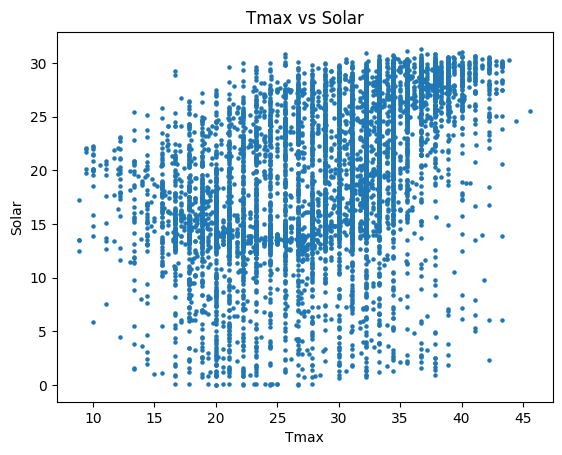

In [4]:
plt.scatter(df["Tmax"], df["Solar"], s=5)
plt.xlabel("Tmax")
plt.ylabel("Solar")
plt.title("Tmax vs Solar")
plt.show()

### Q1.4 Median imputation for numerical data if missing > 10%

In [5]:
pct = df.isnull().mean() * 100                      # % missing in every column
for col in df.select_dtypes("number").columns:
    if pct[col] > 10:
        df[col] = df[col].fillna(df[col].median())
        print(f"{col}: {pct[col]:.1f}% missing -> filled with median")
    else:
        print(f"{col}: {pct[col]:.1f}% missing -> not more than 10%, left as it is")

Tmin: 0.0% missing -> not more than 10%, left as it is
Rainfall: 0.2% missing -> not more than 10%, left as it is
RH: 0.0% missing -> not more than 10%, left as it is
Solar: 0.0% missing -> not more than 10%, left as it is
Wind: 0.0% missing -> not more than 10%, left as it is
Tmax: 0.0% missing -> not more than 10%, left as it is
Discharge: 0.0% missing -> not more than 10%, left as it is


### Q1.5 Remove features with missing values

In [6]:
print("Before:", list(df.columns))
df = df.dropna(axis=1)          # axis=1 = drop COLUMNS that still have a missing value
print("After :", list(df.columns))

Before: ['Date', 'Tmin', 'Rainfall', 'RH', 'Solar', 'Wind', 'Tmax', 'Discharge']
After : ['Date', 'Tmin', 'RH', 'Solar', 'Wind', 'Tmax', 'Discharge']


---
## Question 2

### Q2.1 Read and divide into training (75%) and testing (25%), with preprocessing (scaling)

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

data = pd.read_csv("data/Kasol.csv").dropna()                 # drop the empty lines (and 14 rows with missing Rainfall)
X = StandardScaler().fit_transform(data.drop(columns=["Unnamed: 0", "Solar"]))   # drop the date and the target
y = data["Solar"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (5468, 6)  Test: (1823, 6)


### Q2.2 Build the model and evaluate on the test set (RMSE)

In [8]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error

model = MLPRegressor(hidden_layer_sizes=(32,), max_iter=300, early_stopping=True, random_state=42).fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print("MSE :", round(mse, 4))
print("RMSE:", round(np.sqrt(mse), 4))

MSE : 18.9464
RMSE: 4.3527


### Q2.3 Improve with Randomized Search CV

In [9]:
from sklearn.model_selection import RandomizedSearchCV

params = {"hidden_layer_sizes": [(32,), (64,), (64, 32)], "alpha": [0.0001, 0.001, 0.01], "learning_rate_init": [0.001, 0.01]}
rand = RandomizedSearchCV(MLPRegressor(max_iter=300, early_stopping=True, random_state=42), params,
                          n_iter=5, cv=3, random_state=42).fit(X_train, y_train)
print("Optimal hyperparameters (Randomized):", rand.best_params_)
rmse_rand = np.sqrt(mean_squared_error(y_test, rand.predict(X_test)))
print("RMSE after Randomized Search:", round(rmse_rand, 4))

Optimal hyperparameters (Randomized): {'learning_rate_init': 0.01, 'hidden_layer_sizes': (64, 32), 'alpha': 0.0001}
RMSE after Randomized Search: 4.3519


### Q2.4 Improve with Grid Search CV

In [10]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(MLPRegressor(max_iter=300, early_stopping=True, random_state=42),
                    {"hidden_layer_sizes": [(32,), (64, 32)], "alpha": [0.0001, 0.01]}, cv=3).fit(X_train, y_train)
print("Optimal hyperparameters (Grid):", grid.best_params_)
rmse_grid = np.sqrt(mean_squared_error(y_test, grid.predict(X_test)))
print("RMSE after Grid Search:", round(rmse_grid, 4))

Optimal hyperparameters (Grid): {'alpha': 0.0001, 'hidden_layer_sizes': (64, 32)}
RMSE after Grid Search: 4.2939


### Q2.5 Plot the results

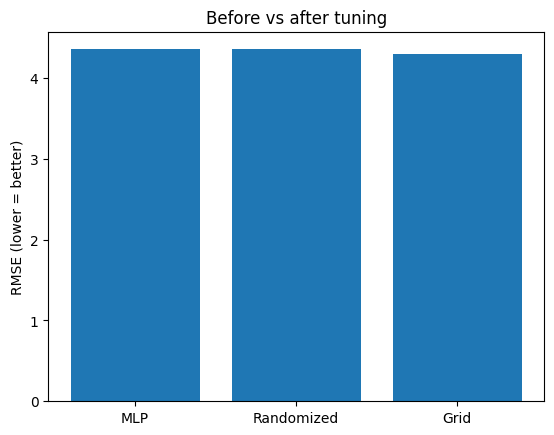

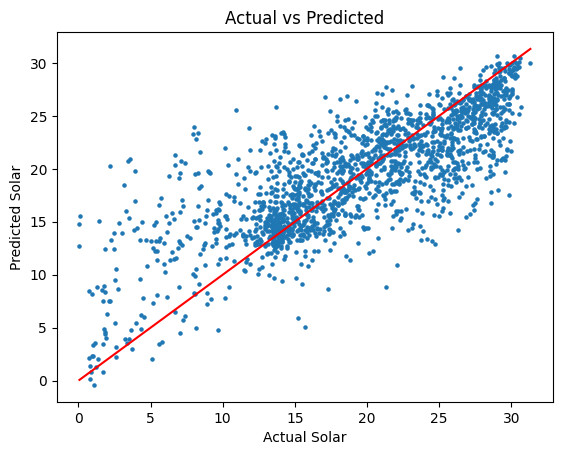

In [11]:
rmse = {"MLP": np.sqrt(mse), "Randomized": rmse_rand, "Grid": rmse_grid}
plt.bar(rmse.keys(), rmse.values())
plt.ylabel("RMSE (lower = better)")
plt.title("Before vs after tuning")
plt.show()

plt.scatter(y_test, grid.predict(X_test), s=5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Actual Solar")
plt.ylabel("Predicted Solar")
plt.title("Actual vs Predicted")
plt.show()